In [1]:
#import torch
import pandas as pd
import os
import numpy as np

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split


In [3]:
NICM_KEY_ = pd.read_csv("Clinical_Data/Clinical_data/NICM_KEY.csv") 
NICM_Data= pd.read_csv("Clinical_Data/Clinical_data/NICM_données_Robert-Mourad.csv") 
pd.set_option('display.max_columns', None)
#col = ["Unnamed: 0","Commentaires MTG","comm sara"]
#clinical_database = clinical_database.drop(columns=col)
#print(clinical_database.shape)
print(NICM_KEY_.dtypes)
print(NICM_KEY_.shape)

NICM_KEY_.head()

MRN             int64
NICM_NUMBER    object
dtype: object
(429, 2)


,MRN,NICM_NUMBER
0,565561,NICM31
1,483253,NICM32
2,590991,NICM33
3,444982,NICM34
4,452297,NICM35


In [4]:
MRN = NICM_KEY_["MRN"].values.tolist()
NICM_NUMBER_key = NICM_KEY_["NICM_NUMBER"].values.tolist()
keys_ = {}
for i , j in zip(NICM_NUMBER_key,MRN):
    keys_[i] = j


d_data = NICM_Data["NICM_NUMBER"].values.tolist()
number_not_exist = []
for n in  d_data:
    if n not in NICM_NUMBER_key:
        number_not_exist.append(n)

print(number_not_exist)

['NICM153', 'NICM156']


In [5]:
print(NICM_Data.shape)
NICM_Data.head()

(431, 59)


,NICM_NUMBER,Panel,Notes,AgeatDx,Sex,Mutation,Gene,VTbeforeDx,DateVTbeforeDx,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR_Strenght,CMR_Device,CMR_LVEF,MRILVvolumeDx,BSA,CMR_LGE,LV_LGE,LV_LGE_distrib_segment_exact,LV_LGE_distrib_wall,LGE_RV_insertion_only,LV_LGE_epi_endo,LV_WMA,RVEF,CMR_More than one,CMR_number,DatesotherCMR,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,Transplant,Date_Transplant,Death,DateOFdeath,CauseDeath_text,LastLVEF,DatelastLVEF,DateLFU,VTAblation,DateVTAblation,DurationFU,DurationFUMRI,LTVA01,T_LTVA01,LTVAafterDx.1,DateLTVAafterDx.1,Unnamed: 56,Unnamed: 57,Unnamed: 58
0,NICM31,CMD,NaN,50,0.0,0,"MYPN,LDB3",0.0,NaN,NaN,NaN,43726.0,43745,1,NaN,17.0,311,1.81,1,1.0,"ehaussement tardif, localisé au niveau sous-en...","1,2,7",0.0,3.4,0,39.0,no,NaN,NaN,0.0,NaN,NaN,1,43929,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,17.0,43745,44896.0,0.0,NaN,3.203285,1151,0,3.203285,0.0,NaN,NaN,NaN,NaN
1,NICM32,CMD,Sténose de la première diagonale a 75%,54,1.0,0,TNNC1,0.0,NaN,NaN,NaN,41788.0,41919,1,NaN,44.0,348,2.12,1,0.0,NaN,NaN,1.0,NaN,0,56.0,no,NaN,NaN,0.0,NaN,NaN,1,43976,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,44.0,41919,44986.0,0.0,NaN,8.755647,3067,0,8.755647,0.0,NaN,NaN,NaN,NaN
2,NICM33,CMD,cardiopathie congénitale - Veine cave sup gauc...,55,1.0,0,NRAP,0.0,NaN,NaN,NaN,43248.0,43503,inconnu,Royal Victoria,50.0,244,NaN,1,0.0,NaN,NaN,1.0,NaN,0,59.0,yes,1,44454,1.0,13580,44447,1,45093,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,35.0,45036,45092.0,0.0,NaN,5.048597,1589,0,5.048597,0.0,NaN,NaN,NaN,NaN
3,NICM34,CMD,Peu d'infos au dossier,44,1.0,0,SCN5A,0.0,NaN,NaN,NaN,43987.0,44001,2,NaN,48.0,250,2.2,1,1.0,sous-épicardique inféro-latéral,5,0.0,1,1,48.0,no,NaN,NaN,1.0,1274,43849,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,50.0,44155,44818.0,0.0,NaN,2.275154,817,0,2.275154,0.0,NaN,NaN,NaN,NaN
4,NICM35,CMD,NaN,49,1.0,0,NaN,0.0,NaN,NaN,NaN,40960.0,40966,1,NaN,21.0,368,2.4,1,1.0,rehaussement tardif en sous-épicarde dans la r...,"1,2,6",0.0,1,0,36.0,yes,4,"2018-07-09,2015-07-06,2013-10-09,2013-03-04",0.0,NaN,NaN,1,43488,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,27.0,45001,45098.0,0.0,NaN,11.329227,4132,0,11.329227,0.0,NaN,NaN,NaN,NaN


In [6]:
NICM_Data = NICM_Data.loc[NICM_Data["VTbeforeDx"] == 0.0]

NICM_Data["label"] = [1 if i >= 1 else 0 for i in NICM_Data["LTVAafterDx"].values.tolist()]
print(NICM_Data.shape)

(413, 60)


In [7]:
NICM_Data["label"].value_counts()

0    369
1     44
Name: label, dtype: int64

In [8]:

missing_percentage = NICM_Data["DateLTVAafterDx.1"].isnull().mean()*100

print("Percentage of missing values for each variable:")
print(100-missing_percentage)

Percentage of missing values for each variable:
10.653753026634377


In [10]:
existed_df = NICM_Data[NICM_Data['NICM_NUMBER'].isin(NICM_NUMBER_key)]
print(existed_df.shape)
existed_df["MRN"] = [keys_[i] for i in existed_df["NICM_NUMBER"].values.tolist()]
#existed_df["label"] = [1 if i >= 1 else 0 for i in existed_df["LTVAafterDx"].values.tolist()]
existed_df.head()


(413, 60)


,NICM_NUMBER,Panel,Notes,AgeatDx,Sex,Mutation,Gene,VTbeforeDx,DateVTbeforeDx,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR_Strenght,CMR_Device,CMR_LVEF,MRILVvolumeDx,BSA,CMR_LGE,LV_LGE,LV_LGE_distrib_segment_exact,LV_LGE_distrib_wall,LGE_RV_insertion_only,LV_LGE_epi_endo,LV_WMA,RVEF,CMR_More than one,CMR_number,DatesotherCMR,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,Transplant,Date_Transplant,Death,DateOFdeath,CauseDeath_text,LastLVEF,DatelastLVEF,DateLFU,VTAblation,DateVTAblation,DurationFU,DurationFUMRI,LTVA01,T_LTVA01,LTVAafterDx.1,DateLTVAafterDx.1,Unnamed: 56,Unnamed: 57,Unnamed: 58,label,MRN
0,NICM31,CMD,NaN,50,0.0,0,"MYPN,LDB3",0.0,NaN,NaN,NaN,43726.0,43745,1,NaN,17.0,311,1.81,1,1.0,"ehaussement tardif, localisé au niveau sous-en...","1,2,7",0.0,3.4,0,39.0,no,NaN,NaN,0.0,NaN,NaN,1,43929,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,17.0,43745,44896.0,0.0,NaN,3.203285,1151,0,3.203285,0.0,NaN,NaN,NaN,NaN,0,565561
1,NICM32,CMD,Sténose de la première diagonale a 75%,54,1.0,0,TNNC1,0.0,NaN,NaN,NaN,41788.0,41919,1,NaN,44.0,348,2.12,1,0.0,NaN,NaN,1.0,NaN,0,56.0,no,NaN,NaN,0.0,NaN,NaN,1,43976,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,44.0,41919,44986.0,0.0,NaN,8.755647,3067,0,8.755647,0.0,NaN,NaN,NaN,NaN,0,483253
2,NICM33,CMD,cardiopathie congénitale - Veine cave sup gauc...,55,1.0,0,NRAP,0.0,NaN,NaN,NaN,43248.0,43503,inconnu,Royal Victoria,50.0,244,NaN,1,0.0,NaN,NaN,1.0,NaN,0,59.0,yes,1,44454,1.0,13580,44447,1,45093,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,35.0,45036,45092.0,0.0,NaN,5.048597,1589,0,5.048597,0.0,NaN,NaN,NaN,NaN,0,590991
3,NICM34,CMD,Peu d'infos au dossier,44,1.0,0,SCN5A,0.0,NaN,NaN,NaN,43987.0,44001,2,NaN,48.0,250,2.2,1,1.0,sous-épicardique inféro-latéral,5,0.0,1,1,48.0,no,NaN,NaN,1.0,1274,43849,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,50.0,44155,44818.0,0.0,NaN,2.275154,817,0,2.275154,0.0,NaN,NaN,NaN,NaN,0,444982
4,NICM35,CMD,NaN,49,1.0,0,NaN,0.0,NaN,NaN,NaN,40960.0,40966,1,NaN,21.0,368,2.4,1,1.0,rehaussement tardif en sous-épicarde dans la r...,"1,2,6",0.0,1,0,36.0,yes,4,"2018-07-09,2015-07-06,2013-10-09,2013-03-04",0.0,NaN,NaN,1,43488,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,27.0,45001,45098.0,0.0,NaN,11.329227,4132,0,11.329227,0.0,NaN,NaN,NaN,NaN,0,452297


In [11]:
import pandas as pd
data = pd.read_parquet("/media/data1/muse_ge/ECG_ad202207_1453937_cat_labels_original_diagnosis_v1.1.parquet")
data.dtypes

index                                         int64
npy_path                                     object
RestingECG_MuseInfo_MuseVersion              object
RestingECG_PatientDemographics_PatientID     object
RestingECG_PatientDemographics_PatientAge    object
                                              ...  
rythme auriculaire gauche                     int64
mauvaise qualité de l'ecg                     int64
bloc de branche droit                         int64
hémibloc antérieur gauche                     int64
dictionary_diagnosis                         object
Length: 583, dtype: object

In [12]:
MRN = existed_df["MRN"].values.tolist()
MRN = [str(x).zfill(7) for x in MRN]
existed_df["MRN"] = MRN
# Now try creating the subset
data_ = data.loc[data['RestingECG_PatientDemographics_PatientID'].isin(MRN)]

data_.shape

(5003, 583)

In [76]:
data_.head(2)

,index,npy_path,RestingECG_MuseInfo_MuseVersion,RestingECG_PatientDemographics_PatientID,RestingECG_PatientDemographics_PatientAge,RestingECG_PatientDemographics_AgeUnits,RestingECG_PatientDemographics_DateofBirth,RestingECG_PatientDemographics_Gender,RestingECG_PatientDemographics_PatientLastName,RestingECG_PatientDemographics_PatientFirstName,RestingECG_TestDemographics_DataType,RestingECG_TestDemographics_Site,RestingECG_TestDemographics_SiteName,RestingECG_TestDemographics_AcquisitionDevice,RestingECG_TestDemographics_Status,RestingECG_TestDemographics_EditListStatus,RestingECG_TestDemographics_Priority,RestingECG_TestDemographics_Location,RestingECG_TestDemographics_LocationName,RestingECG_TestDemographics_AcquisitionTime,RestingECG_TestDemographics_AcquisitionDate,RestingECG_TestDemographics_CartNumber,RestingECG_TestDemographics_AcquisitionSoftwareVersion,RestingECG_TestDemographics_AnalysisSoftwareVersion,RestingECG_TestDemographics_EditTime,RestingECG_TestDemographics_EditDate,RestingECG_TestDemographics_OverreaderID,RestingECG_TestDemographics_EditorID,RestingECG_TestDemographics_OrderingMDLastName,RestingECG_TestDemographics_OrderingMDFirstName,RestingECG_TestDemographics_ReferringMDLastName,RestingECG_TestDemographics_ReferringMDFirstName,RestingECG_TestDemographics_OverreaderLastName,RestingECG_TestDemographics_OverreaderFirstName,RestingECG_TestDemographics_EditorLastName,RestingECG_TestDemographics_EditorFirstName,RestingECG_TestDemographics_HISStatus,RestingECG_Order_RequisitionNumber,RestingECG_Order_HISOrderNumber,RestingECG_Order_HISAccountNumber,RestingECG_Order_HISTestType,RestingECG_Order_OrderingMDHISID,RestingECG_Order_HISOrderingMDLastName,RestingECG_Order_HISOrderingMDFirstName,RestingECG_Order_OrderTime,RestingECG_Order_HISLocation,RestingECG_Order_ExtraADTData1,RestingECG_Order_ExtraOrderData1,RestingECG_Order_ExtraOrderData2,RestingECG_Order_HISDisposition,RestingECG_Order_ReferringMDHISID,RestingECG_Order_AdmissionType,RestingECG_Order_PlacersHISID,RestingECG_Order_PlacersLastName,RestingECG_Order_PlacersFirstName,RestingECG_Order_OrderPlacementDate,RestingECG_Order_OrderPlacementTime,RestingECG_RestingECGMeasurements_VentricularRate,RestingECG_RestingECGMeasurements_AtrialRate,RestingECG_RestingECGMeasurements_QRSDuration,RestingECG_RestingECGMeasurements_QTInterval,RestingECG_RestingECGMeasurements_QTCorrected,RestingECG_RestingECGMeasurements_PAxis,RestingECG_RestingECGMeasurements_RAxis,RestingECG_RestingECGMeasurements_TAxis,RestingECG_RestingECGMeasurements_QRSCount,RestingECG_RestingECGMeasurements_QOnset,RestingECG_RestingECGMeasurements_QOffset,RestingECG_RestingECGMeasurements_TOffset,RestingECG_RestingECGMeasurements_ECGSampleBase,RestingECG_RestingECGMeasurements_ECGSampleExponent,RestingECG_RestingECGMeasurements_QTcFrederica,RestingECG_OriginalRestingECGMeasurements_VentricularRate,RestingECG_OriginalRestingECGMeasurements_AtrialRate,RestingECG_OriginalRestingECGMeasurements_QRSDuration,RestingECG_OriginalRestingECGMeasurements_QTInterval,RestingECG_OriginalRestingECGMeasurements_QTCorrected,RestingECG_OriginalRestingECGMeasurements_PAxis,RestingECG_OriginalRestingECGMeasurements_RAxis,RestingECG_OriginalRestingECGMeasurements_TAxis,RestingECG_OriginalRestingECGMeasurements_QRSCount,RestingECG_OriginalRestingECGMeasurements_QOnset,RestingECG_OriginalRestingECGMeasurements_QOffset,RestingECG_OriginalRestingECGMeasurements_TOffset,RestingECG_OriginalRestingECGMeasurements_ECGSampleBase,RestingECG_OriginalRestingECGMeasurements_ECGSampleExponent,RestingECG_OriginalRestingECGMeasurements_QTcFrederica,RestingECG_ExtraQuestions_ExtraQuestion_Question,RestingECG_ExtraQuestions_ExtraQuestion_Answer,RestingECG_QRSTimesTypes_GlobalRR,RestingECG_QRSTimesTypes_QTRGGR,RestingECG_PharmaData_PharmaCartID,RestingECG_TestDemographics_TestReason,RestingECG_RestingECGMeasurements_SystolicBP,RestingECG_RestingECGMeasurements_DiastolicBP,RestingECG_RestingECGMeasurements_PRInterval,RestingECG_OriginalRes

In [13]:
MRN = existed_df["MRN"].values.tolist()
NICM_NUMBER_key = existed_df["LTVAafterDx"].values.tolist()
keys_ = {}
for i , j in zip(MRN,NICM_NUMBER_key):
    keys_[i] = j


label = []
feature = []

sub_set_ID = data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    feature.append(existed_df.loc[existed_df['MRN'] == patient_ID, :].values.flatten())
    #label.append(int(keys_[patient_ID]))
feature = pd.DataFrame(feature, columns=existed_df.columns)
feature.head()

,NICM_NUMBER,Panel,Notes,AgeatDx,Sex,Mutation,Gene,VTbeforeDx,DateVTbeforeDx,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR_Strenght,CMR_Device,CMR_LVEF,MRILVvolumeDx,BSA,CMR_LGE,LV_LGE,LV_LGE_distrib_segment_exact,LV_LGE_distrib_wall,LGE_RV_insertion_only,LV_LGE_epi_endo,LV_WMA,RVEF,CMR_More than one,CMR_number,DatesotherCMR,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,Transplant,Date_Transplant,Death,DateOFdeath,CauseDeath_text,LastLVEF,DatelastLVEF,DateLFU,VTAblation,DateVTAblation,DurationFU,DurationFUMRI,LTVA01,T_LTVA01,LTVAafterDx.1,DateLTVAafterDx.1,Unnamed: 56,Unnamed: 57,Unnamed: 58,label,MRN
0,NICM122,CMD,NaN,57,1.0,1,TTN,0.0,NaN,NaN,NaN,43770.0,43991,2,3 Tesla,21.0,439,2.32,1,1.0,Rehaussement myocardique tardif inféroseptal b...,"1,2,3,5,6,7",1.0,1.2,1,34.0,no,NaN,NaN,0.0,NaN,NaN,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,55.0,45016,45021.0,0.0,NaN,3.425051,1030,0,3.425051,0.0,NaN,NaN,NaN,NaN,0,0113058
1,NICM122,CMD,NaN,57,1.0,1,TTN,0.0,NaN,NaN,NaN,43770.0,43991,2,3 Tesla,21.0,439,2.32,1,1.0,Rehaussement myocardique tardif inféroseptal b...,"1,2,3,5,6,7",1.0,1.2,1,34.0,no,NaN,NaN,0.0,NaN,NaN,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,55.0,45016,45021.0,0.0,NaN,3.425051,1030,0,3.425051,0.0,NaN,NaN,NaN,NaN,0,0113058
2,NICM122,CMD,NaN,57,1.0,1,TTN,0.0,NaN,NaN,NaN,43770.0,43991,2,3 Tesla,21.0,439,2.32,1,1.0,Rehaussement myocardique tardif inféroseptal b...,"1,2,3,5,6,7",1.0,1.2,1,34.0,no,NaN,NaN,0.0,NaN,NaN,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,55.0,45016,45021.0,0.0,NaN,3.425051,1030,0,3.425051,0.0,NaN,NaN,NaN,NaN,0,0113058
3,NICM122,CMD,NaN,57,1.0,1,TTN,0.0,NaN,NaN,NaN,43770.0,43991,2,3 Tesla,21.0,439,2.32,1,1.0,Rehaussement myocardique tardif inféroseptal b...,"1,2,3,5,6,7",1.0,1.2,1,34.0,no,NaN,NaN,0.0,NaN,NaN,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,55.0,45016,45021.0,0.0,NaN,3.425051,1030,0,3.425051,0.0,NaN,NaN,NaN,NaN,0,0113058
4,NICM122,CMD,NaN,57,1.0,1,TTN,0.0,NaN,NaN,NaN,43770.0,43991,2,3 Tesla,21.0,439,2.32,1,1.0,Rehaussement myocardique tardif inféroseptal b...,"1,2,3,5,6,7",1.0,1.2,1,34.0,no,NaN,NaN,0.0,NaN,NaN,0,NaN,0.0,NaN,NaN,0.0,NaN,NaN,0.0,NaN,0.0,NaN,NaN,55.0,45016,45021.0,0.0,NaN,3.425051,1030,0,3.425051,0.0,NaN,NaN,NaN,NaN,0,0113058


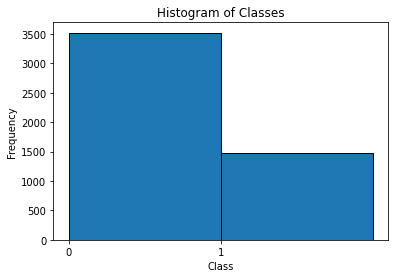

the number of ones :1481 with percentage : 29.60223865680592%
the number of zeros :3522 with percentage : 70.39776134319409%
the total is : 5003


In [16]:
plt.hist(label, bins=[0, 1, 2.0], edgecolor='black')  # Specifying bin edges for discrete classes
plt.xlabel('Class')
plt.ylabel('Frequency')
plt.title(f'Histogram of Classes')
plt.xticks([0, 1])  # Setting ticks for discrete classes
plt.show()
print("the number of ones :"+str(label.count(1))+ " with percentage : "+str((label.count(1)/len(label))*100)+"%")
print("the number of zeros :"+str(label.count(0))+ " with percentage : "+str((label.count(0)/len(label))*100)+"%")
print("the total is :",len(label))

In [17]:
threshold = 55

# Calculate the percentage of missing values for each column
missing_percentage = (existed_df.isna().mean() * 100).round(2)

# Filter columns based on the threshold
columns_above_threshold = missing_percentage[missing_percentage > threshold].index.tolist()
# Print or use the list of columns
print("Columns with more than {}% missing values:".format(threshold))
print(columns_above_threshold)


Columns with more than 55% missing values:
['Notes', 'DateVTbeforeDx', 'Amino Acid', 'DNA Change', 'CMR_number', 'DatesotherCMR', 'MaxHolterPVCcountDx', 'DateHolterDx', 'Date_ICDimplantation', 'DateLTVAafterDx', 'LTVAafterDx_CL', 'DateSevereLTVAafterDx', 'SevereLTVAafterDx_CL', 'Date_Transplant', 'DateOFdeath', 'CauseDeath_text', 'DateVTAblation', 'DateLTVAafterDx.1', 'Unnamed: 56', 'Unnamed: 57', 'Unnamed: 58']


In [18]:
missing_percentage

NICM_NUMBER      0.00
Panel            0.24
Notes           94.67
AgeatDx          0.00
Sex              0.00
                ...  
Unnamed: 56     99.27
Unnamed: 57    100.00
Unnamed: 58    100.00
label            0.00
MRN              0.00
Length: 61, dtype: float64

In [19]:
s = ["NICM_NUMBER","MRN","label","AgeatDx","Sex","Mutation","CMR_LVEF","LV_LGE","ICD"]
k = [i.lower() for i in columns_above_threshold]
columns_above_threshold = [i for i in  columns_above_threshold if i!="DateLTVAafterDx"]
for i in s:
    if i.lower() in k:
        print(i)

In [20]:
merged_df = existed_df.drop(columns=columns_above_threshold)

In [21]:
d = merged_df.columns
s = []
for i in d:
    if "date" in i.lower():
        s.append(i)
print(s)

['DateFirstFU', 'Date_FirstMRI', 'DateLTVAafterDx', 'DatelastLVEF', 'DateLFU']


In [22]:
date = ['DateFirstFU', 'Date_FirstMRI', 'DateLTVAafterDx', 'DatelastLVEF', 'DateLFU']

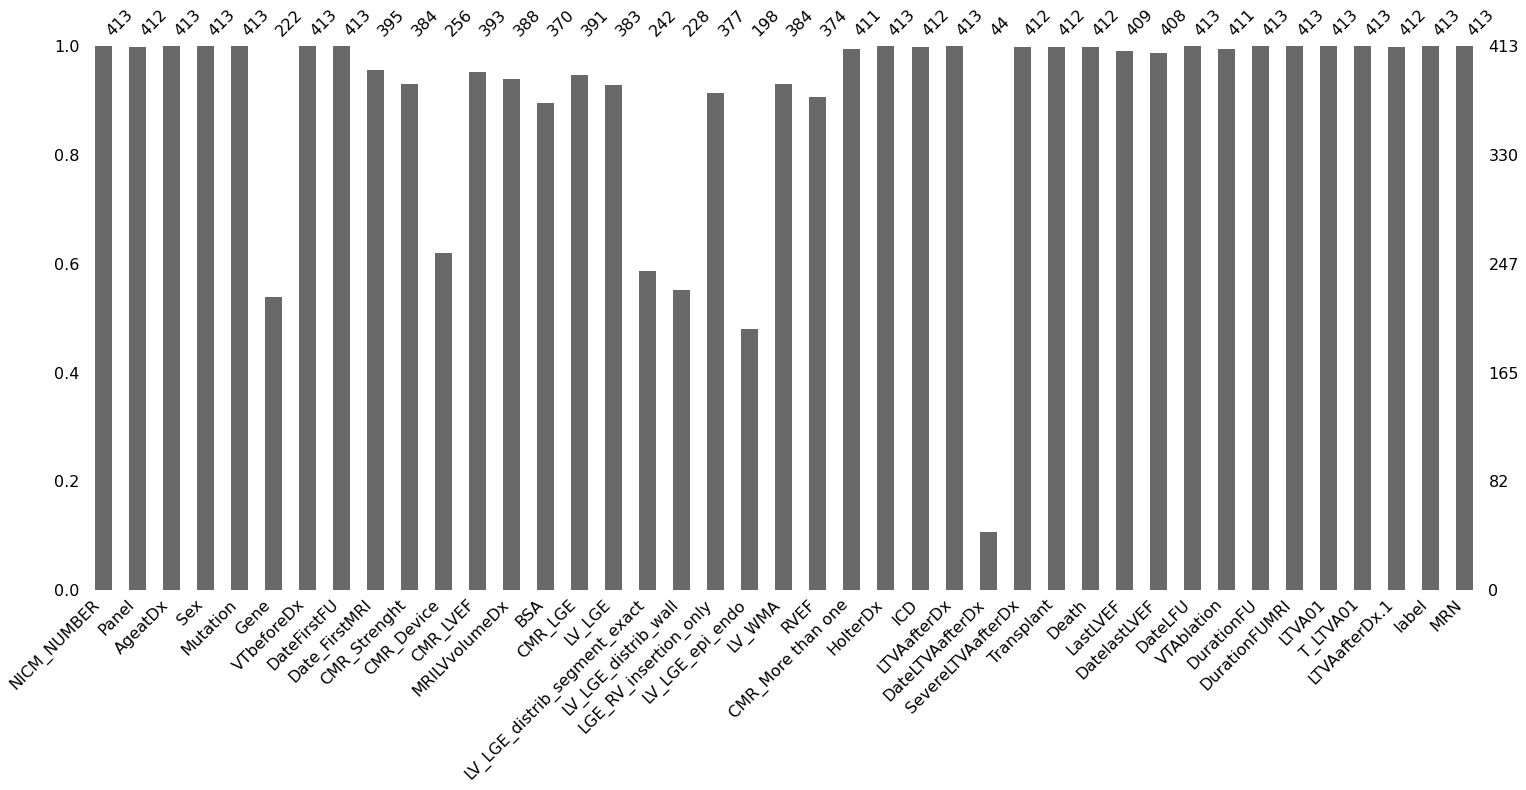

In [23]:
import missingno as msno
import matplotlib.pyplot as plt
msno.bar(merged_df)
plt.show()

<ipython-input-31-9cac34c5978f>:9: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matrix = merged_df.corr()


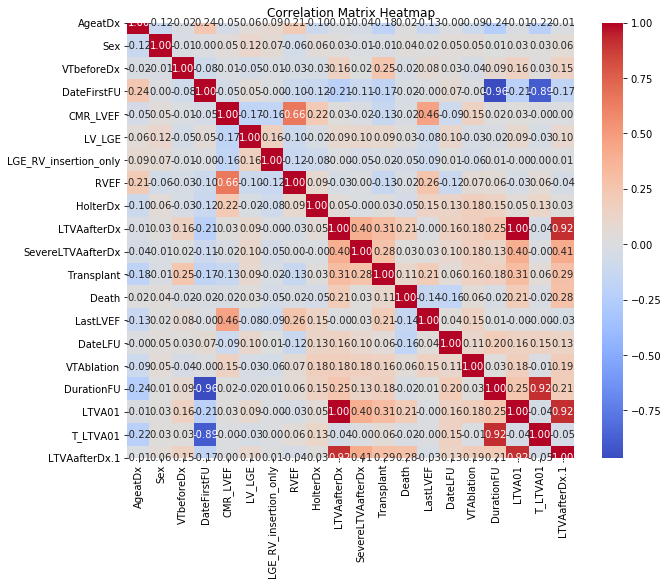

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming you have a DataFrame named 'df' with your data
# For example, df = pd.read_csv('your_data.csv')

# Calculate the correlation matrix
correlation_matrix = merged_df.corr()

# Create a heatmap using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix Heatmap')
plt.show()


In [25]:
s = date + ["NICM_NUMBER","MRN","label","AgeatDx","CMR_LVEF","Sex","Mutation","LV_LGE"]
selected_df = merged_df[s]
selected_df.head()

,DateFirstFU,Date_FirstMRI,DateLTVAafterDx,DatelastLVEF,DateLFU,NICM_NUMBER,MRN,label,AgeatDx,CMR_LVEF,Sex,Mutation,LV_LGE
0,43726.0,43745,NaN,43745,44896.0,NICM31,0565561,0,50,17.0,0.0,0,1.0
1,41788.0,41919,NaN,41919,44986.0,NICM32,0483253,0,54,44.0,1.0,0,0.0
2,43248.0,43503,NaN,45036,45092.0,NICM33,0590991,0,55,50.0,1.0,0,0.0
3,43987.0,44001,NaN,44155,44818.0,NICM34,0444982,0,44,48.0,1.0,0,1.0
4,40960.0,40966,NaN,45001,45098.0,NICM35,0452297,0,49,21.0,1.0,0,1.0


In [26]:
selected_df.loc[selected_df["Mutation"]=="inconnu", "Mutation"] = '0'
#selected_df.loc[selected_df["ICD"]=="inconnu", "ICD"] = '0'
mean_age = selected_df['CMR_LVEF'].mean()
selected_df['CMR_LVEF'].fillna(mean_age, inplace=True)
selected_df['LV_LGE'].fillna(0.0, inplace=True)
#selected_df['ICD'].fillna("0", inplace=True)



/usr/local/lib/python3.8/dist-packages/pandas/core/indexing.py:1817: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value, pi)
/usr/local/lib/python3.8/dist-packages/pandas/core/generic.py:6392: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  return self._update_inplace(result)


In [27]:
missing_percentage = (selected_df[s[7:]].isna().mean() * 100).round(2)
print(missing_percentage)

label       0.0
AgeatDx     0.0
CMR_LVEF    0.0
Sex         0.0
Mutation    0.0
LV_LGE      0.0
dtype: float64


In [28]:
selected_df.head()

,DateFirstFU,Date_FirstMRI,DateLTVAafterDx,DatelastLVEF,DateLFU,NICM_NUMBER,MRN,label,AgeatDx,CMR_LVEF,Sex,Mutation,LV_LGE
0,43726.0,43745,NaN,43745,44896.0,NICM31,0565561,0,50,17.0,0.0,0,1.0
1,41788.0,41919,NaN,41919,44986.0,NICM32,0483253,0,54,44.0,1.0,0,0.0
2,43248.0,43503,NaN,45036,45092.0,NICM33,0590991,0,55,50.0,1.0,0,0.0
3,43987.0,44001,NaN,44155,44818.0,NICM34,0444982,0,44,48.0,1.0,0,1.0
4,40960.0,40966,NaN,45001,45098.0,NICM35,0452297,0,49,21.0,1.0,0,1.0


In [29]:
cat_features = selected_df.drop(columns=date + ['NICM_NUMBER','MRN','label',"AgeatDx","CMR_LVEF"])
cat = []
for i in cat_features.columns:
    cat.append(pd.get_dummies(cat_features[i],prefix=i).astype(int))

X_train_ = pd.concat([selected_df[date + ["NICM_NUMBER","MRN","label","AgeatDx","CMR_LVEF"]]]+cat, axis=1)
X_train_.head()

,DateFirstFU,Date_FirstMRI,DateLTVAafterDx,DatelastLVEF,DateLFU,NICM_NUMBER,MRN,label,AgeatDx,CMR_LVEF,Sex_0.0,Sex_1.0,Mutation_0,Mutation_1,LV_LGE_0.0,LV_LGE_1.0
0,43726.0,43745,NaN,43745,44896.0,NICM31,0565561,0,50,17.0,1,0,1,0,0,1
1,41788.0,41919,NaN,41919,44986.0,NICM32,0483253,0,54,44.0,0,1,1,0,1,0
2,43248.0,43503,NaN,45036,45092.0,NICM33,0590991,0,55,50.0,0,1,1,0,1,0
3,43987.0,44001,NaN,44155,44818.0,NICM34,0444982,0,44,48.0,0,1,1,0,0,1
4,40960.0,40966,NaN,45001,45098.0,NICM35,0452297,0,49,21.0,0,1,1,0,0,1


(95, 8)


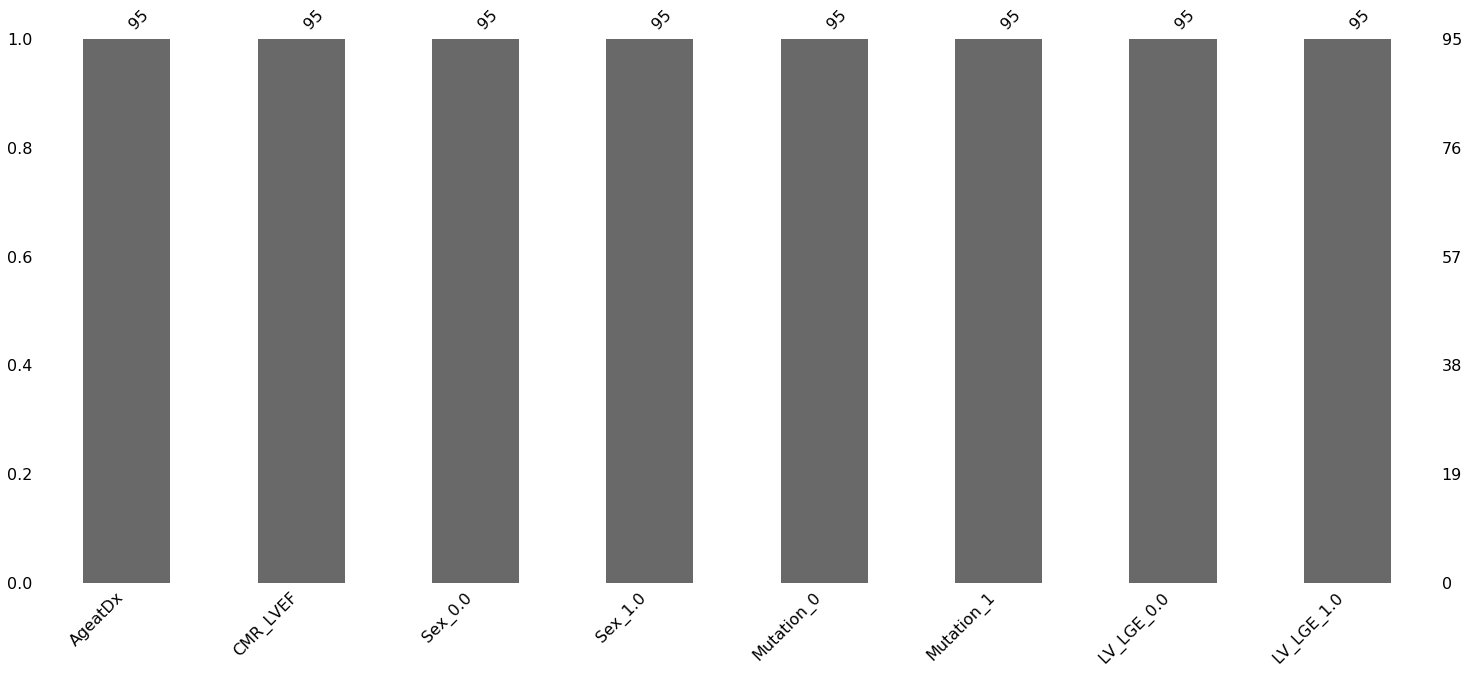

In [47]:
import missingno as msno
import matplotlib.pyplot as plt
print(X_test.shape)
msno.bar(X_test)
plt.show()

In [48]:
print(X_train_.shape)
X_train_.head()

(429, 12)


,NICM_NUMBER,MRN,label,DateLTVAafterDx,AgeatDx,CMR_LVEF,Sex_0.0,Sex_1.0,Mutation_0,Mutation_1,LV_LGE_0.0,LV_LGE_1.0
0,NICM31,0565561,0,NaN,50,17.0,1,0,1,0,0,1
1,NICM32,0483253,0,NaN,54,44.0,0,1,1,0,1,0
2,NICM33,0590991,0,NaN,55,50.0,0,1,1,0,1,0
3,NICM34,0444982,0,NaN,44,48.0,0,1,1,0,0,1
4,NICM35,0452297,0,NaN,49,21.0,0,1,1,0,0,1


In [30]:
import pickle

# Load the list from the .pkl file
with open('NICM_Test_ids_list.pkl', 'rb') as file:
    l = pickle.load(file)

data_test = selected_df.loc[selected_df['MRN'].isin(l)]
train_data = selected_df.loc[~selected_df['MRN'].isin(l)]
print(f"In the test set: the mean of ages is {data_test['AgeatDx'].mean()}. the Max age is :{data_test['AgeatDx'].max()}. the Min age is {data_test['AgeatDx'].min()}")

print("**************************************************************************")

print(f"In the train set: the mean of ages is {train_data['AgeatDx'].mean()}. the Max age is :{train_data['AgeatDx'].max()}. the Min age is {train_data['AgeatDx'].min()}")

print("Statistic about the gander:")
print("In the test set:")
print(data_test["Sex"].value_counts())
print("In the train set:")
print(train_data["Sex"].value_counts())

In the test set: the mean of ages is 48.31111111111111. the Max age is :78. the Min age is 16
**************************************************************************
In the train set: the mean of ages is 49.1578947368421. the Max age is :77. the Min age is 16
Statistic about the gander:
In the test set:
1.0    65
0.0    25
Name: Sex, dtype: int64
In the train set:
1.0    213
0.0    110
Name: Sex, dtype: int64
